# BigData – mecze rankingowe League of Legends w MongoDB

**Problem:** co decyduje o wygranej w meczu rankingowym League of Legends (Solo/Duo)? Badamy przewagę strony mapy, znaczenie „pierwszych” celów (first blood, pierwsza wieża, smok…), przewagę złota w trakcie gry i siłę championów.

**Źródło danych:** oficjalne, udokumentowane [Riot Games API](https://developer.riotgames.com/apis):
* [`match-v5`](https://developer.riotgames.com/apis#match-v5): szczegóły meczu (`/lol/match/v5/matches/{matchId}`) i timeline minuta po minucie (`/lol/match/v5/matches/{matchId}/timeline`),
* [`league-v4`](https://developer.riotgames.com/apis#league-v4): ranga gracza (`/lol/league/v4/entries/by-puuid/{puuid}`).

**Architektura aplikacji:**

```
Riot API ──► collector (pobieranie) ──► data/raw/*.jsonl.gz ──► importer.py ──► MongoDB (Docker)
                                                                                │
                              wykresy i zestawienia ◄── pandas / scipy ◄── agregacje MongoDB
```

1. **Pobieranie:** osobna aplikacja [League-Of-Legends-Data-Collector](https://github.com/Stifanox/League-Of-Legends-Data-Collector) odpytuje API (limity zapytań, wznawianie, losowanie meczów warstwowo po randze) i zapisuje odpowiedzi **bez zmian** jako gzip JSON Lines.
2. **Zapis:** `importer.py` wczytuje surowe pliki równolegle i zapisuje dokumenty w lokalnej bazie MongoDB uruchomionej w Dockerze (`docker-compose.yml`).
3. **Przetwarzanie i czyszczenie:** potoki agregacji MongoDB sprawdzają poprawność danych i budują oczyszczoną kolekcję `games`.
4. **Analizy statystyczne i prezentacja:** agregacje MongoDB, testy statystyczne (`scipy`), wykresy (`matplotlib`) i tabele.

**Uruchomienie** (szczegóły w `README.md`):
```bash
cd bigdata
sudo docker compose up -d            # MongoDB na 127.0.0.1:27017
python importer.py                   # lub komórka "Import" poniżej
```

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient
from scipy import stats

import importer

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

BLUE, RED, GREY = '#2a78d6', '#d64541', '#8a8a8a'
TIERS = ['IRON', 'BRONZE', 'SILVER', 'GOLD', 'PLATINUM', 'EMERALD', 'DIAMOND',
         'MASTER', 'GRANDMASTER', 'CHALLENGER']

client = MongoClient(importer.MONGO_URI, serverSelectionTimeoutMS=5000)
db = client[importer.DB_NAME]
print('MongoDB', client.server_info()['version'], '| baza:', importer.DB_NAME)


def agg(collection, pipeline):
    # wynik potoku agregacji jako DataFrame
    return pd.DataFrame(list(db[collection].aggregate(pipeline, allowDiskUse=True)))


IMG_DIR = Path('sprawozdanie/img')
IMG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    # wykres trafia też do sprawozdania (sprawozdanie/img/<name>.png)
    plt.savefig(IMG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')


def wilson(k, n, z=1.96):
    # 95% przedział ufności Wilsona dla proporcji k/n
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

MongoDB 8.0.34 | baza: lol


## 1. Import danych do MongoDB

Importer (`importer.py`) przetwarza każdy plik `part-NNNN.jsonl.gz` w osobnym procesie (8 procesów) i wstawia dokumenty partiami po 500 (`insert_many`, `ordered=False`):

| kolekcja | `_id` | zawartość |
|---|---|---|
| `matches` | `match_id` | **pełna** odpowiedź `match-v5` (ok. 76 KB, ok. 150 pól na gracza) |
| `timelines` | `match_id` | okrojony timeline: sumy złota, XP i CS drużyn w każdej minucie, stan graczy w minutach 10/15/20, kluczowe zdarzenia (zabójstwa, smoki, wieże, płytki). Pełny timeline ma ok. 0,8 MB na mecz, a w bazie zostaje ok. 25 KB. |
| `ranks` | `puuid\|fetched_at` | odpowiedź `league-v4` (ranga gracza w chwili zapytania) |

Unikalny `_id` sprawia, że **duplikaty są odrzucane już przy imporcie** (i liczone), a import można bezpiecznie powtórzyć. Wstawione zostaną tylko brakujące dokumenty.

Import uruchamia się tylko wtedy, gdy baza jest pusta. Katalog z danymi to `importer.RAW_DIR`; można go zmienić zmienną środowiskową `LOL_RAW_DIR` przed uruchomieniem Jupytera.

In [2]:
RUN_IMPORT = db.matches.estimated_document_count() == 0
print('Katalog z surowymi danymi:', importer.RAW_DIR)

if RUN_IMPORT:
    importer.run_import(raw_dir=importer.RAW_DIR, workers=8)
else:
    print('Baza już zaimportowana - pomijam import (ustaw RUN_IMPORT = True, aby uzupełnić braki).')

Katalog z surowymi danymi: /home/stifano/Projects/League-Of-Legends-Data-Collector/data/raw
Baza już zaimportowana - pomijam import (ustaw RUN_IMPORT = True, aby uzupełnić braki).


In [3]:
# statystyki zapisane przez importer: rozmiar spakowany (gz_bytes) i po rozpakowaniu (raw_bytes)
imp = pd.DataFrame(json.loads(importer.STATS_FILE.read_text()).values())
imp['spakowane_GB'] = imp.gz_bytes / 1e9
imp['rozpakowane_GB'] = imp.raw_bytes / 1e9
source = imp.groupby('kind').agg(pliki=('file', 'size'), spakowane_GB=('spakowane_GB', 'sum'),
                                 rozpakowane_GB=('rozpakowane_GB', 'sum'), rekordy=('lines', 'sum'),
                                 wstawione=('inserted', 'sum'), duplikaty=('duplicates', 'sum'),
                                 uszkodzone_linie=('bad_lines', 'sum'))
source.loc['RAZEM'] = source.sum()
source

,pliki,spakowane_GB,rozpakowane_GB,rekordy,wstawione,duplikaty,uszkodzone_linie
kind,,,,,,,
matches,27,2.3329,15.9433,203018,203018,0,0
ranks,28,0.3635,0.6793,1147754,1147754,0,0
timelines,111,13.7084,155.2263,203018,203018,0,0
RAZEM,166,16.4048,171.8489,1553790,1553790,0,0


In [4]:
dbs = db.command('dbStats')
coll_stats = pd.DataFrame([
    {'kolekcja': c,
     'dokumenty': (s := db.command('collStats', c))['count'],
     'rozmiar_danych_GB': s['size'] / 1e9,
     'na_dysku_GB': s['storageSize'] / 1e9,
     'średni_dokument_KB': s.get('avgObjSize', 0) / 1024}
    for c in ('matches', 'timelines', 'ranks')]).set_index('kolekcja')
coll_stats.loc['RAZEM'] = coll_stats.sum()
coll_stats.loc['RAZEM', 'średni_dokument_KB'] = np.nan
print(f"Baza '{importer.DB_NAME}' (wszystkie kolekcje): dane {dbs['dataSize'] / 1e9:.1f} GB, "
      f"na dysku (kompresja zstd) {dbs['storageSize'] / 1e9:.1f} GB, indeksy {dbs['indexSize'] / 1e9:.2f} GB")
coll_stats

Baza 'lol' (wszystkie kolekcje): dane 22.0 GB, na dysku (kompresja zstd) 3.4 GB, indeksy 0.33 GB


,dokumenty,rozmiar_danych_GB,na_dysku_GB,średni_dokument_KB
kolekcja,,,,
matches,203018,15.8769,2.4809,76.3711
timelines,203018,4.9204,0.6970,23.6680
ranks,1147754,0.7696,0.1351,0.6543
RAZEM,1553790,21.5669,3.3129,NaN


**Wolumen danych:** surowe dane z API to **ok. 172 GB po rozpakowaniu** (16,4 GB spakowane), czyli ok. 1,55 mln rekordów. Wymóg min. 5 GB jest spełniony z dużym zapasem. Do MongoDB trafia z tego ok. 21,6 GB dokumentów (pełne mecze ok. 16 GB, okrojone timeline'y ok. 5 GB, rangi ok. 0,8 GB). Dzięki kompresji zstd zajmują one na dysku tylko ok. 3,3 GB. Import zajmuje ok. 5 minut na 8 procesach.

Przykładowy dokument meczu (skrót: pierwszy poziom zagnieżdżenia i wybrane pola gracza):

In [5]:
doc = db.matches.find_one({}, {'info.participants': {'$slice': 1}, 'metadata': 0})
print({k: type(v).__name__ for k, v in doc.items()})
print('info:', sorted(doc['info'].keys()))
p = doc['info']['participants'][0]
print(f"participants[0]: {len(p)} pól, np.", {k: p[k] for k in ('championName', 'teamId', 'teamPosition', 'kills', 'deaths', 'assists', 'goldEarned', 'win')})
print('teams[0].objectives:', db.matches.find_one({}, {'info.teams.objectives': 1})['info']['teams'][0]['objectives'])

{'_id': 'str', 'platform_id': 'str', 'fetched_at': 'datetime', 'seed_tier': 'str', 'strategy': 'str', 'info': 'dict'}
info: ['endOfGameResult', 'gameCreation', 'gameDuration', 'gameEndTimestamp', 'gameId', 'gameMode', 'gameName', 'gameStartTimestamp', 'gameType', 'gameVersion', 'mapId', 'participants', 'platformId', 'queueId', 'teams', 'tournamentCode']
participants[0]: 156 pól, np. {'championName': 'Nasus', 'teamId': 100, 'teamPosition': 'TOP', 'kills': 3, 'deaths': 13, 'assists': 3, 'goldEarned': 14597, 'win': False}
teams[0].objectives: {'baron': {'first': False, 'kills': 0}, 'champion': {'first': True, 'kills': 32}, 'dragon': {'first': True, 'kills': 3}, 'horde': {'first': True, 'kills': 3}, 'inhibitor': {'first': False, 'kills': 0}, 'riftHerald': {'first': True, 'kills': 1}, 'tower': {'first': True, 'kills': 7}, 'voidGator': {'first': False, 'kills': 0}}


## 2. Sprawdzanie i czyszczenie danych

Sprawdzamy kolejno:
1. **Duplikaty**: odrzucone przy imporcie przez unikalny `_id` (tabela wyżej).
2. **Typ meczu**: czy wszystkie mecze to ranked Solo/Duo (`queueId = 420`) na Summoner's Rift (`mapId = 11`).
3. **Mecze nieukończone**: `endOfGameResult != GameComplete` (przerwane przez anti-cheat).
4. **Remake'i i mecze z graczem, który wyszedł**: bardzo krótkie mecze zakończone poddaniem.
5. **Spójność struktury**: 10 graczy, 2 drużyny, dokładnie jeden zwycięzca, flagi `win` graczy zgodne z drużyną, przypisane role (`teamPosition`).
6. **Kompletność**: czy każdy mecz ma timeline i jaka część graczy ma pobraną rangę.

In [6]:
checks = agg('matches', [
    {'$project': {
        'queue': '$info.queueId', 'map': '$info.mapId', 'result': '$info.endOfGameResult',
        'duration': '$info.gameDuration',
        'early_surrender': {'$arrayElemAt': ['$info.participants.gameEndedInEarlySurrender', 0]},
        'surrender': {'$arrayElemAt': ['$info.participants.gameEndedInSurrender', 0]},
        'n_players': {'$size': '$info.participants'},
        'n_teams': {'$size': '$info.teams'},
        'n_winning_teams': {'$size': {'$filter': {'input': '$info.teams', 'cond': '$$this.win'}}},
        'n_winning_players': {'$size': {'$filter': {'input': '$info.participants', 'cond': '$$this.win'}}},
        'n_no_position': {'$size': {'$filter': {'input': '$info.participants', 'cond': {'$eq': ['$$this.teamPosition', '']}}}},
        'n_afk': {'$size': {'$filter': {'input': '$info.participants', 'cond': '$$this.wasAfk'}}},
    }},
    {'$group': {
        '_id': None,
        'mecze': {'$sum': 1},
        'queue_inna_niz_420': {'$sum': {'$cond': [{'$ne': ['$queue', 420]}, 1, 0]}},
        'mapa_inna_niz_11': {'$sum': {'$cond': [{'$ne': ['$map', 11]}, 1, 0]}},
        'nieukonczone': {'$sum': {'$cond': [{'$ne': ['$result', 'GameComplete']}, 1, 0]}},
        'remake_early_surrender': {'$sum': {'$cond': ['$early_surrender', 1, 0]}},
        'krotsze_niz_10min_bez_remake': {'$sum': {'$cond': [{'$and': [{'$lt': ['$duration', 600]}, {'$not': ['$early_surrender']}]}, 1, 0]}},
        'liczba_graczy_inna_niz_10': {'$sum': {'$cond': [{'$ne': ['$n_players', 10]}, 1, 0]}},
        'liczba_druzyn_inna_niz_2': {'$sum': {'$cond': [{'$ne': ['$n_teams', 2]}, 1, 0]}},
        'zwyciezcow_druzyn_inna_niz_1': {'$sum': {'$cond': [{'$ne': ['$n_winning_teams', 1]}, 1, 0]}},
        'zwyciezcow_graczy_inna_niz_5': {'$sum': {'$cond': [{'$ne': ['$n_winning_players', 5]}, 1, 0]}},
        'gracz_bez_roli': {'$sum': {'$cond': [{'$gt': ['$n_no_position', 0]}, 1, 0]}},
        'gracz_afk': {'$sum': {'$cond': [{'$gt': ['$n_afk', 0]}, 1, 0]}},
    }},
]).drop(columns='_id').T.rename(columns={0: 'liczba meczów'})
checks['udział'] = checks['liczba meczów'] / checks.loc['mecze', 'liczba meczów']
checks

,liczba meczów,udział
mecze,203018,1.0000
queue_inna_niz_420,0,0.0000
mapa_inna_niz_11,0,0.0000
nieukonczone,10,0.0000
remake_early_surrender,4130,0.0203
krotsze_niz_10min_bez_remake,1621,0.0080
liczba_graczy_inna_niz_10,0,0.0000
liczba_druzyn_inna_niz_2,0,0.0000
zwyciezcow_druzyn_inna_niz_1,10,0.0000
zwyciezcow_graczy_inna_niz_5,10,0.0000


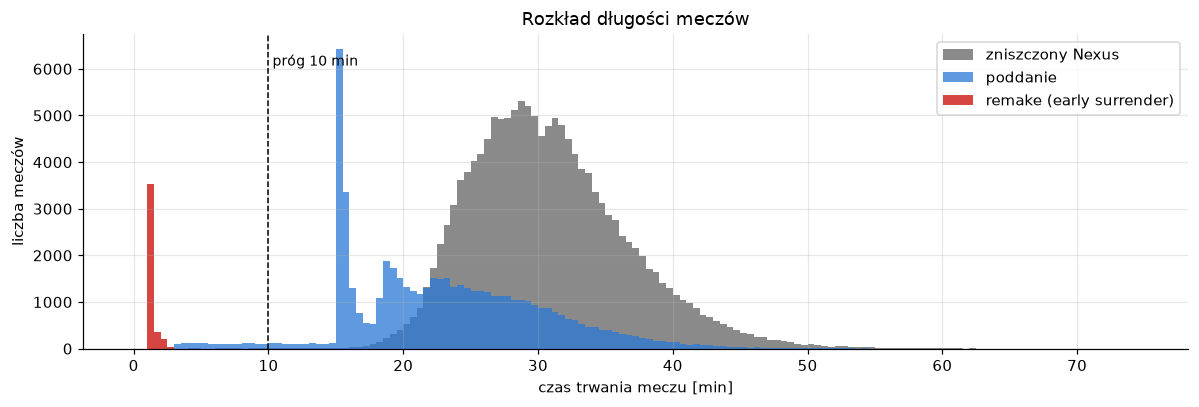

In [7]:
durations = agg('matches', [
    {'$project': {'_id': 0, 'minuty': {'$divide': ['$info.gameDuration', 60]},
                  'early': {'$arrayElemAt': ['$info.participants.gameEndedInEarlySurrender', 0]},
                  'surrender': {'$arrayElemAt': ['$info.participants.gameEndedInSurrender', 0]}}},
])
fig, ax = plt.subplots(figsize=(11, 3.8))
bins = np.arange(0, 75, 0.5)
ax.hist(durations.loc[~durations.early & ~durations.surrender, 'minuty'], bins=bins, color=GREY, label='zniszczony Nexus')
ax.hist(durations.loc[durations.surrender, 'minuty'], bins=bins, color=BLUE, alpha=0.75, label='poddanie')
ax.hist(durations.loc[durations.early, 'minuty'], bins=bins, color=RED, label='remake (early surrender)')
ax.axvline(10, color='black', ls='--', lw=1)
ax.text(10.3, ax.get_ylim()[1] * 0.9, 'próg 10 min', fontsize=9)
ax.set_xlabel('czas trwania meczu [min]')
ax.set_ylabel('liczba meczów')
ax.set_title('Rozkład długości meczów')
ax.legend()
plt.tight_layout()
save_fig('dlugosc_meczow')
plt.show()

In [8]:
tl = agg('matches', [
    {'$lookup': {'from': 'timelines', 'localField': '_id', 'foreignField': '_id', 'as': 't',
                 'pipeline': [{'$project': {'_id': 1}}]}},
    {'$group': {'_id': None, 'mecze': {'$sum': 1},
                'z_timeline': {'$sum': {'$cond': [{'$gt': [{'$size': '$t'}, 0]}, 1, 0]}}}},
])
print(f"Mecze z timeline'em: {tl.z_timeline[0]:,} / {tl.mecze[0]:,} ({tl.z_timeline[0] / tl.mecze[0]:.2%})")

rank_status = agg('ranks', [{'$group': {'_id': '$status', 'odpowiedzi': {'$sum': 1}}}]).set_index('_id')
print(rank_status)
players_total = agg('matches', [{'$unwind': '$metadata.participants'},
                                {'$group': {'_id': '$metadata.participants'}}, {'$count': 'n'}]).n[0]
ranked_players = agg('ranks', [{'$group': {'_id': '$puuid'}}, {'$count': 'n'}]).n[0]
print(f'Unikalnych graczy w meczach: {players_total:,}, z pobraną rangą: {ranked_players:,} ({ranked_players / players_total:.1%})')

Mecze z timeline'em: 203,018 / 203,018 (100.00%)


          odpowiedzi
_id                 
RANKED       1137492
UNRANKED       10262


Unikalnych graczy w meczach: 929,192, z pobraną rangą: 839,301 (90.3%)


**Wnioski i decyzje:**

| problem | liczba meczów | decyzja |
|---|---|---|
| duplikaty rekordów | 0 (odrzucane przez `_id`) | zabezpieczenie zostaje (crawler może zapisać rekord dwa razy po awarii) |
| uszkodzone linie JSON | 0 | jw. |
| inna kolejka lub mapa | 0 | filtr `queueId = 420`, `mapId = 11` zostaje w potoku |
| mecz nieukończony (anti-cheat), brak zwycięzcy | 10 | **usuwamy** (bez wyniku nie da się ich analizować; to te same 10 meczów, które nie mają dokładnie 1 zwycięskiej drużyny) |
| remake (`gameEndedInEarlySurrender`, < 3 min) | 4 130 (2,0%) | **usuwamy**, bo mecz się nie odbył |
| poddanie przed 10. minutą | 1 621 (0,8%) | **usuwamy**, bo to mecze z graczem, który wyszedł, i nie odzwierciedlają normalnej rozgrywki |
| gracz bez przypisanej roli (`teamPosition = ''`) | 457 (0,2%) | **usuwamy**, bo rola jest potrzebna w analizie championów |
| gracz oznaczony jako AFK (`wasAfk`) | 13 580 (6,7%) | **zostawiamy**, bo to część realiów gier rankingowych, a nie błąd danych |

* Struktura dokumentów jest spójna: zawsze 10 graczy, 2 drużyny, a flagi `win` graczy zgadzają się z drużyną (poza 10 przerwanymi meczami).
* Każdy mecz ma timeline. Rangę pobrano dla ok. 90% unikalnych graczy, z czego ok. 1% to gracze bez rangi (`UNRANKED`). W analizach poziom meczu określamy przez `seed_tier` (ranga gracza, przez którego mecz został znaleziony), bo jest dostępny dla 100% meczów.
* Rozkład długości meczów ma charakterystyczne piki: przy **15 min** (pierwsza możliwość poddania) i przy **ok. 20 min** (od tego momentu poddanie nie wymaga jednomyślności), a mecze zakończone zniszczeniem Nexusa trwają typowo 25–35 min.

### 2.1. Budowa oczyszczonej kolekcji `games`

Jeden potok agregacji (`$match` → `$project` → `$out`) wybiera poprawne mecze i zapisuje dla każdego zwarty dokument: metadane, wynik, cele drużyn i 10 graczy (champion, rola, KDA, złoto). Następnie drugi potok dołącza z `timelines` różnicę złota i XP drużyn w minutach 10, 15 i 20 (`$merge`). Wszystkie analizy działają na `games` (ok. 2 KB na mecz zamiast 76 KB).

In [9]:
VALID = {
    'info.queueId': 420,
    'info.mapId': 11,
    'info.endOfGameResult': 'GameComplete',
    'info.gameDuration': {'$gte': 600},
    'info.participants.0.gameEndedInEarlySurrender': False,
    'info.participants.teamPosition': {'$ne': ''},
    'info.participants': {'$size': 10},
}

db.matches.aggregate([
    {'$match': VALID},
    {'$project': {
        'platform_id': 1,
        'seed_tier': 1,
        'patch': {'$let': {'vars': {'v': {'$split': ['$info.gameVersion', '.']}},
                           'in': {'$concat': [{'$arrayElemAt': ['$$v', 0]}, '.', {'$arrayElemAt': ['$$v', 1]}]}}},
        'game_start': {'$toDate': '$info.gameStartTimestamp'},
        'duration_min': {'$divide': ['$info.gameDuration', 60]},
        'surrender': {'$arrayElemAt': ['$info.participants.gameEndedInSurrender', 0]},
        'blue_win': {'$anyElementTrue': [{'$map': {'input': '$info.teams',
                                                   'in': {'$and': [{'$eq': ['$$this.teamId', 100]}, '$$this.win']}}}]},
        'teams': {'$map': {'input': '$info.teams', 'in': {
            'team_id': '$$this.teamId', 'win': '$$this.win', 'objectives': '$$this.objectives'}}},
        'players': {'$map': {'input': '$info.participants', 'in': {
            'team_id': '$$this.teamId', 'win': '$$this.win', 'champion': '$$this.championName',
            'position': '$$this.teamPosition', 'kills': '$$this.kills', 'deaths': '$$this.deaths',
            'assists': '$$this.assists', 'gold': '$$this.goldEarned'}}},
    }},
    {'$out': 'games'},
], allowDiskUse=True)

# różnica złota / XP (blue - red) w minutach 10, 15, 20 z kolekcji timelines
db.timelines.aggregate([
    {'$project': {'frames': {'$filter': {'input': '$team_frames', 'cond': {'$in': ['$$this.minute', [10, 15, 20]]}}}}},
    {'$project': {
        'gold_diff': {'$arrayToObject': {'$map': {'input': '$frames', 'in': {
            'k': {'$concat': ['m', {'$toString': '$$this.minute'}]},
            'v': {'$subtract': ['$$this.blue.gold', '$$this.red.gold']}}}}},
        'xp_diff': {'$arrayToObject': {'$map': {'input': '$frames', 'in': {
            'k': {'$concat': ['m', {'$toString': '$$this.minute'}]},
            'v': {'$subtract': ['$$this.blue.xp', '$$this.red.xp']}}}}},
    }},
    {'$merge': {'into': 'games', 'on': '_id', 'whenMatched': 'merge', 'whenNotMatched': 'discard'}},
], allowDiskUse=True)

db.games.create_index('seed_tier')
db.games.create_index('platform_id')
n_games = db.games.count_documents({})
n_matches = db.matches.estimated_document_count()
print(f'games: {n_games:,} meczów ({n_games / n_matches:.2%} z {n_matches:,}), '
      f"średnio {db.command('collStats', 'games')['avgObjSize'] / 1024:.1f} KB na dokument")
print('z różnicą złota w 15. min:', db.games.count_documents({'gold_diff.m15': {'$exists': True}}))
db.games.find_one({}, {'players': {'$slice': 2}})

games: 197,142 meczów (97.11% z 203,018), średnio 2.0 KB na dokument
z różnicą złota w 15. min: 196191


{'_id': 'NA1_5660959823',
 'platform_id': 'NA1',
 'seed_tier': 'MASTER',
 'patch': '16.20',
 'game_start': datetime.datetime(2026, 10, 15, 23, 55, 14, 261000),
 'duration_min': 36.483333333333334,
 'surrender': False,
 'blue_win': False,
 'teams': [{'team_id': 100,
   'win': False,
   'objectives': {'baron': {'first': False, 'kills': 0},
    'champion': {'first': True, 'kills': 32},
    'dragon': {'first': True, 'kills': 3},
    'horde': {'first': True, 'kills': 3},
    'inhibitor': {'first': False, 'kills': 0},
    'riftHerald': {'first': True, 'kills': 1},
    'tower': {'first': True, 'kills': 7},
    'voidGator': {'first': False, 'kills': 0}}},
  {'team_id': 200,
   'win': True,
   'objectives': {'baron': {'first': True, 'kills': 2},
    'champion': {'first': False, 'kills': 34},
    'dragon': {'first': False, 'kills': 3},
    'horde': {'first': False, 'kills': 0},
    'inhibitor': {'first': True, 'kills': 1},
    'riftHerald': {'first': False, 'kills': 0},
    'tower': {'first': Fa

### 2.2. Statystyki opisowe oczyszczonego zbioru

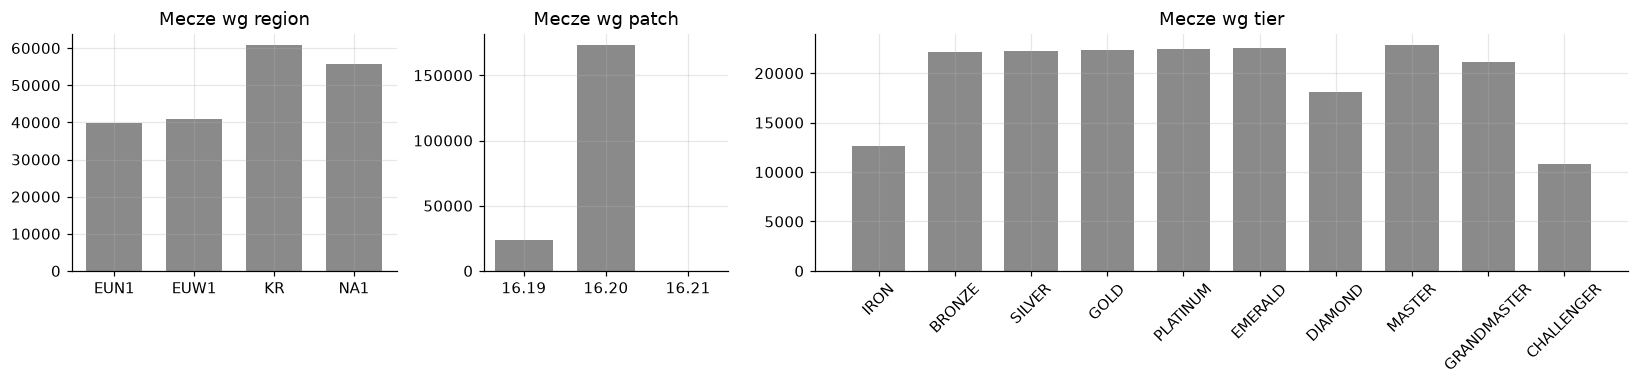

,count,mean,std,min,25%,50%,75%,max
duration_min,"197,142.0000",28.7487,6.9613,10.0000,24.3667,28.6500,33.0833,74.8500
kills,"197,142.0000",63.4988,21.0507,3.0000,49.0000,63.0000,77.0000,203.0000
gold_diff_15,"196,191.0000",20.5584,"4,207.1739","-18,558.0000","-2,722.0000",4.0000,"2,742.0000","21,924.0000"


In [10]:
overview = agg('games', [
    {'$facet': {
        'region': [{'$group': {'_id': '$platform_id', 'n': {'$sum': 1}}}],
        'patch': [{'$group': {'_id': '$patch', 'n': {'$sum': 1}}}],
        'tier': [{'$group': {'_id': '$seed_tier', 'n': {'$sum': 1}}}],
    }},
])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={'width_ratios': [4, 3, 10]})
for ax, key in zip(axes, ['region', 'patch', 'tier']):
    d = pd.DataFrame(overview[key][0]).set_index('_id').n
    d = d.reindex(TIERS) if key == 'tier' else d.sort_index()
    ax.bar(d.index, d.values, color=GREY, width=0.7)
    ax.set_title(f'Mecze wg {key}')
    ax.tick_params(axis='x', rotation=45 if key == 'tier' else 0)
plt.tight_layout()
save_fig('mecze_wg_kategorii')
plt.show()

desc = agg('games', [
    {'$project': {'_id': 0, 'duration_min': 1, 'surrender': 1,
                  'kills': {'$sum': '$players.kills'}, 'gold_diff_15': '$gold_diff.m15'}},
])
desc.describe().T

## 3. Analiza 1: przewaga strony mapy (blue vs red)

Drużyna niebieska (blue, `teamId = 100`) zaczyna w lewym dolnym rogu mapy, a czerwona (red) w prawym górnym. Strony różnią się położeniem smoka i Barona oraz kątem kamery. **Hipoteza zerowa H₀:** P(blue wygrywa) = 0,5. Stosujemy dokładny test dwumianowy dla całego zbioru, a przedziały ufności Wilsona i test χ² jednorodności dla rang.

Blue win rate: 0.4987 (95% CI 0.4965–0.5009), n = 197,142, p-value testu dwumianowego = 2.42e-01
Test χ² jednorodności - rangi: χ² = 115.3, p = 1.25e-20; regiony: χ² = 48.5, p = 1.69e-10


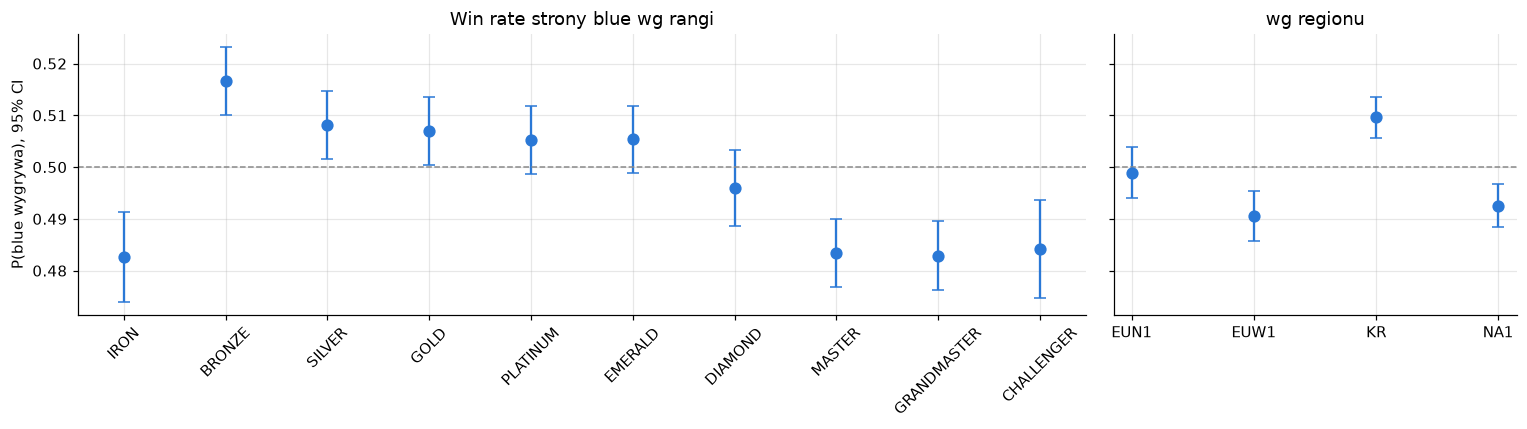

n  blue_wins  blue_win_rate  ci_low  ci_high
ranga  IRON         12610       6086         0.4826  0.4739   0.4914
       BRONZE       22101      11418         0.5166  0.5100   0.5232
       SILVER       22238      11300         0.5081  0.5016   0.5147
       GOLD         22363      11338         0.5070  0.5004   0.5135
       PLATINUM     22453      11343         0.5052  0.4986   0.5117
       EMERALD      22509      11375         0.5054  0.4988   0.5119
       DIAMOND      18143       8998         0.4959  0.4887   0.5032
       MASTER       22803      11023         0.4834  0.4769   0.4899
       GRANDMASTER  21088      10184         0.4829  0.4762   0.4897
       CHALLENGER   10834       5246         0.4842  0.4748   0.4936
region EUN1         39897      19904         0.4989  0.4940   0.5038
       EUW1         40872      20048         0.4905  0.4857   0.4954
       KR           60714      30943         0.5097  0.5057   0.5136
       NA1          55659      27416         0.4926  0.4884   0.4967

In [11]:
side = agg('games', [
    {'$group': {'_id': {'tier': '$seed_tier', 'region': '$platform_id'},
                'n': {'$sum': 1}, 'blue_wins': {'$sum': {'$cond': ['$blue_win', 1, 0]}}}},
])
side = pd.concat([side.drop(columns='_id'), pd.json_normalize(side['_id'])], axis=1)

n, k = side.n.sum(), side.blue_wins.sum()
test = stats.binomtest(int(k), int(n), 0.5)
lo, hi = wilson(k, n)
print(f'Blue win rate: {k / n:.4f} (95% CI {lo:.4f}–{hi:.4f}), n = {n:,}, p-value testu dwumianowego = {test.pvalue:.2e}')

def side_table(by):
    t = side.groupby(by)[['n', 'blue_wins']].sum()
    t['blue_win_rate'] = t.blue_wins / t.n
    t['ci_low'], t['ci_high'] = wilson(t.blue_wins, t.n)
    chi2, p, dof, _ = stats.chi2_contingency(np.c_[t.blue_wins, t.n - t.blue_wins])
    return t, chi2, p

by_tier, chi_t, p_t = side_table('tier')
by_tier = by_tier.reindex(TIERS)
by_region, chi_r, p_r = side_table('region')
print(f'Test χ² jednorodności - rangi: χ² = {chi_t:.1f}, p = {p_t:.3g}; regiony: χ² = {chi_r:.1f}, p = {p_r:.3g}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [10, 4]}, sharey=True)
for ax, t in zip(axes, [by_tier, by_region]):
    x = np.arange(len(t))
    ax.errorbar(x, t.blue_win_rate, yerr=[t.blue_win_rate - t.ci_low, t.ci_high - t.blue_win_rate],
                fmt='o', color=BLUE, ms=7, capsize=4)
    ax.axhline(0.5, color=GREY, ls='--', lw=1)
    ax.set_xticks(x, t.index, rotation=45 if len(t) > 4 else 0)
axes[0].set_ylabel('P(blue wygrywa), 95% CI')
axes[0].set_title('Win rate strony blue wg rangi')
axes[1].set_title('wg regionu')
plt.tight_layout()
save_fig('strona_mapy')
plt.show()
pd.concat({'ranga': by_tier, 'region': by_region})

**Wnioski:**
* **W całym zbiorze strona mapy nie daje przewagi:** blue wygrywa w 49,87% meczów (95% CI 49,65–50,09%), a test dwumianowy nie odrzuca H₀ (p = 0,24).
* **Przewaga zależy jednak od rangi i regionu** (test χ²: p ≈ 10⁻²⁰ dla rang, p ≈ 10⁻¹⁰ dla regionów). W niskich i średnich rangach (BRONZE–EMERALD) blue wygrywa w 50,5–51,7% meczów. W **MASTER, GRANDMASTER i CHALLENGER** (oraz w IRON) przewagę ma **red** (blue tylko ok. 48,3%). W Korei blue wygrywa w 51,0%, w EUW tylko w 49,1%.
* Możliwe wyjaśnienie (hipoteza, nie wynika wprost z danych): red wybiera championa jako ostatni (*counter-pick*), co doświadczeni gracze potrafią wykorzystać, a Smok leży po stronie red.
* Efekty są **istotne statystycznie, ale małe** (±2 p.p.). Przy ok. 200 tys. meczów nawet drobne różnice są wykrywalne.

## 4. Analiza 2: znaczenie „pierwszych” celów

Dla każdego celu (first blood, pierwsza wieża, pierwszy smok, voidgruby, Rift Herald, pierwszy inhibitor, Baron) liczymy win rate drużyny, która zdobyła go **pierwsza**. Siłę związku mierzymy **ilorazem szans (odds ratio)** z testem χ² niezależności dla tabeli 2×2 (zdobył pierwszy × wygrał).

Analizę wykonujemy na poziomie drużyny (`$unwind` po `teams`), więc każdy mecz daje dwie obserwacje.

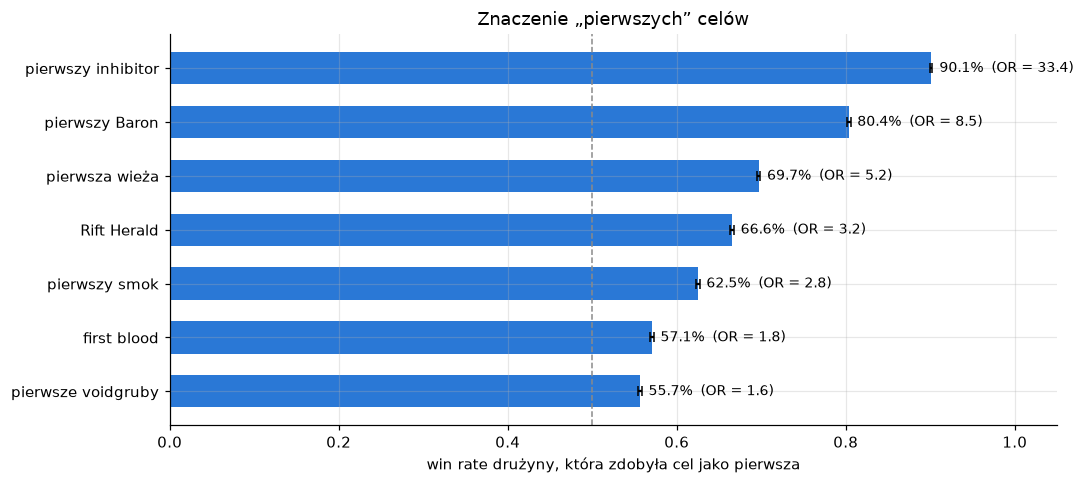

,drużyn_z_celem,win_rate_gdy_pierwszy,ci_low,ci_high,win_rate_gdy_nie,odds_ratio,chi2,p_value
cel,,,,,,,,
pierwszy inhibitor,164318,0.9008,0.8993,0.9022,0.2136,33.4266,"181,021.7899",0.0000
pierwszy Baron,143982,0.8036,0.8016,0.8057,0.3253,8.4873,"83,642.5239",0.0000
pierwsza wieża,196344,0.6969,0.6948,0.6989,0.3047,5.2459,"60,637.3949",0.0000
Rift Herald,163116,0.6656,0.6633,0.6679,0.3831,3.2054,"30,530.5893",0.0000
pierwszy smok,196798,0.6250,0.6229,0.6272,0.3754,2.7737,"24,574.3724",0.0000
first blood,197064,0.5707,0.5685,0.5729,0.4293,1.7673,"7,883.9339",0.0000
pierwsze voidgruby,196380,0.5566,0.5544,0.5588,0.4438,1.5735,"5,020.2130",0.0000


In [12]:
OBJECTIVES = {'champion': 'first blood', 'tower': 'pierwsza wieża', 'dragon': 'pierwszy smok',
              'horde': 'pierwsze voidgruby', 'riftHerald': 'Rift Herald', 'inhibitor': 'pierwszy inhibitor',
              'baron': 'pierwszy Baron'}

obj = agg('games', [
    {'$unwind': '$teams'},
    {'$project': {'win': '$teams.win', **{o: f'$teams.objectives.{o}.first' for o in OBJECTIVES}}},
    {'$facet': {o: [{'$group': {'_id': {'first': f'${o}', 'win': '$win'}, 'n': {'$sum': 1}}}] for o in OBJECTIVES}},
])

rows = []
for o, label in OBJECTIVES.items():
    t = pd.DataFrame([{**r['_id'], 'n': r['n']} for r in obj[o][0]]).pivot(index='first', columns='win', values='n').fillna(0)
    a, b = t.loc[True, True], t.loc[True, False]        # zdobył pierwszy: wygrane / przegrane
    c, d = t.loc[False, True], t.loc[False, False]      # nie zdobył pierwszy
    chi2, p, _, _ = stats.chi2_contingency([[a, b], [c, d]])
    lo, hi = wilson(a, a + b)
    rows.append({'cel': label, 'drużyn_z_celem': int(a + b), 'win_rate_gdy_pierwszy': a / (a + b),
                 'ci_low': lo, 'ci_high': hi, 'win_rate_gdy_nie': c / (c + d),
                 'odds_ratio': (a * d) / (b * c), 'chi2': chi2, 'p_value': p})
objectives = pd.DataFrame(rows).set_index('cel').sort_values('win_rate_gdy_pierwszy')

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(objectives))
ax.barh(y, objectives.win_rate_gdy_pierwszy, color=BLUE, height=0.6)
ax.errorbar(objectives.win_rate_gdy_pierwszy, y, xerr=[objectives.win_rate_gdy_pierwszy - objectives.ci_low,
            objectives.ci_high - objectives.win_rate_gdy_pierwszy], fmt='none', color='black', capsize=3)
for yi, v, orr in zip(y, objectives.win_rate_gdy_pierwszy, objectives.odds_ratio):
    ax.text(v + 0.01, yi, f'{v:.1%}  (OR = {orr:.1f})', va='center', fontsize=9)
ax.axvline(0.5, color=GREY, ls='--', lw=1)
ax.set_yticks(y, objectives.index)
ax.set_xlim(0, 1.05)
ax.set_xlabel('win rate drużyny, która zdobyła cel jako pierwsza')
ax.set_title('Znaczenie „pierwszych” celów')
plt.tight_layout()
save_fig('pierwsze_cele')
plt.show()
objectives.sort_values('odds_ratio', ascending=False)

**Wnioski:**
* Wszystkie cele są istotnie związane z wygraną (p ≈ 0 we wszystkich testach χ²), ale **siła związku bardzo się różni**:
  * **pierwszy inhibitor** (90% wygranych, OR ≈ 33) i **pierwszy Baron** (80%, OR ≈ 8,5) to cele późnej gry. Zdobywa je zwykle drużyna, która już wygrywa, więc to raczej **skutek** przewagi niż jej przyczyna,
  * **pierwsza wieża** to najsilniejszy wskaźnik z wczesnej gry: 69,7% wygranych (OR ≈ 5,2),
  * **Rift Herald** 66,6%, **pierwszy smok** 62,5%,
  * **first blood** (57,1%) i **pierwsze voidgruby** (55,7%) dają tylko niewielką przewagę.
* To analiza **korelacyjna**: zdobycie celu jest jednocześnie oznaką i źródłem przewagi, więc nie mierzy „czystego” wpływu przyczynowego.

## 5. Analiza 3: przewaga złota w trakcie gry a wygrana

Z timeline'ów (kolekcja `timelines` dołączona do `games`) mamy różnicę złota blue − red w minutach 10, 15 i 20. Dzielimy ją na przedziały co 1000 złota (`$bucket` w MongoDB) i liczymy w nich odsetek wygranych blue. Następnie dopasowujemy **regresję logistyczną** P(wygrana) = σ(β·Δgold) i sprawdzamy, **jak często drużyna przegrywająca w 15. minucie odwraca wynik (comeback)** w zależności od rangi (test χ²).

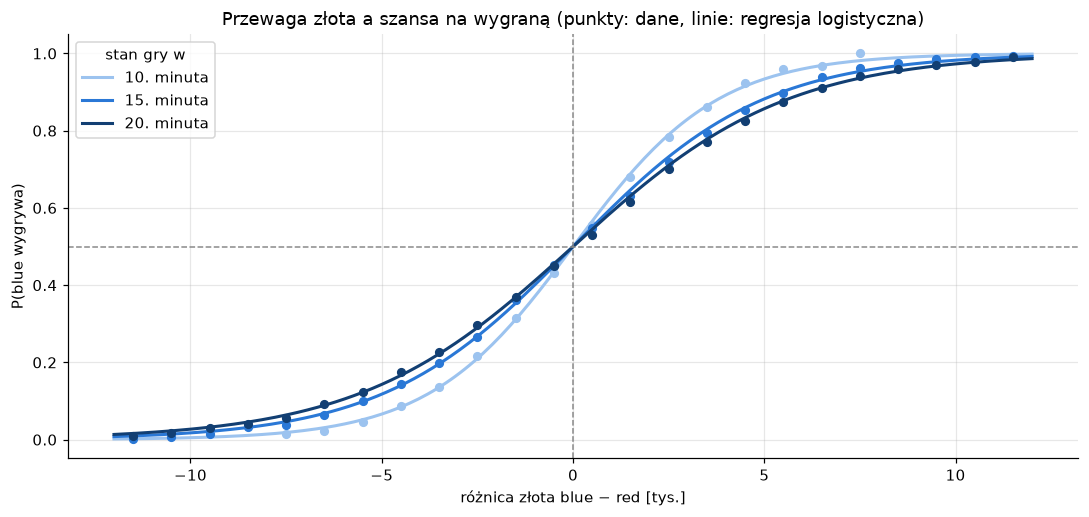

,n,beta_na_1000_zlota,zloto_dla_P75,trafnosc_znak_przewagi
minuta,,,,
10.0000,"196,191.0000",0.5294,"2,075.3535",0.6912
15.0000,"196,191.0000",0.4028,"2,727.5064",0.7452
20.0000,"179,416.0000",0.3580,"3,068.4457",0.7757


In [13]:
edges = list(range(-12000, 12001, 1000))
curves = {}
for m in (10, 15, 20):
    b = agg('games', [
        {'$match': {f'gold_diff.m{m}': {'$exists': True}}},
        {'$bucket': {'groupBy': f'$gold_diff.m{m}', 'boundaries': edges, 'default': 'poza',
                     'output': {'n': {'$sum': 1}, 'blue_wins': {'$sum': {'$cond': ['$blue_win', 1, 0]}}}}},
    ])
    b = b[b._id != 'poza'].assign(mid=lambda d: d._id.astype(float) + 500, rate=lambda d: d.blue_wins / d.n)
    curves[m] = b[b.n >= 100]

gd = agg('games', [{'$match': {'gold_diff.m15': {'$exists': True}}},
                   {'$project': {'_id': 0, 'blue_win': 1, 'seed_tier': 1,
                                 'g10': '$gold_diff.m10', 'g15': '$gold_diff.m15', 'g20': '$gold_diff.m20'}}])


def fit_logistic(x, y):
    # regresja logistyczna jednej zmiennej (MLE): P(y=1) = 1 / (1 + exp(-(a + b x)))
    def nll(params):
        z = params[0] + params[1] * x
        return np.sum(np.logaddexp(0, z) - y * z)
    from scipy.optimize import minimize
    return minimize(nll, x0=[0.0, 0.0], method='BFGS').x


fits = {}
for m in (10, 15, 20):
    d = gd.dropna(subset=[f'g{m}'])
    a, b = fit_logistic(d[f'g{m}'].values / 1000, d.blue_win.values.astype(float))
    fits[m] = {'minuta': m, 'n': len(d), 'beta_na_1000_zlota': b,
               'zloto_dla_P75': np.log(3) / b * 1000,
               'trafnosc_znak_przewagi': ((d[f'g{m}'] > 0) == d.blue_win).mean()}
fits = pd.DataFrame(fits).T.set_index('minuta')

fig, ax = plt.subplots(figsize=(10, 4.8))
xs = np.linspace(-12, 12, 200)
for m, color in zip((10, 15, 20), ['#9cc3ef', BLUE, '#123f73']):
    c = curves[m]
    ax.plot(c.mid / 1000, c.rate, 'o', color=color, ms=5)
    ax.plot(xs, 1 / (1 + np.exp(-fits.loc[m, 'beta_na_1000_zlota'] * xs)), color=color, lw=2, label=f'{m}. minuta')
ax.axhline(0.5, color=GREY, ls='--', lw=1)
ax.axvline(0, color=GREY, ls='--', lw=1)
ax.set_xlabel('różnica złota blue − red [tys.]')
ax.set_ylabel('P(blue wygrywa)')
ax.set_title('Przewaga złota a szansa na wygraną (punkty: dane, linie: regresja logistyczna)')
ax.legend(title='stan gry w')
plt.tight_layout()
save_fig('przewaga_zlota')
plt.show()
fits

Comeback przy stracie >= 3000 złota w 15. min: 11.77% z 90,381 meczów
Test χ² jednorodności między rangami: χ² = 173.2, df = 9, p = 1.36e-32; korelacja Spearmana ranga ↔ comeback: ρ = -0.12 (p = 0.751)


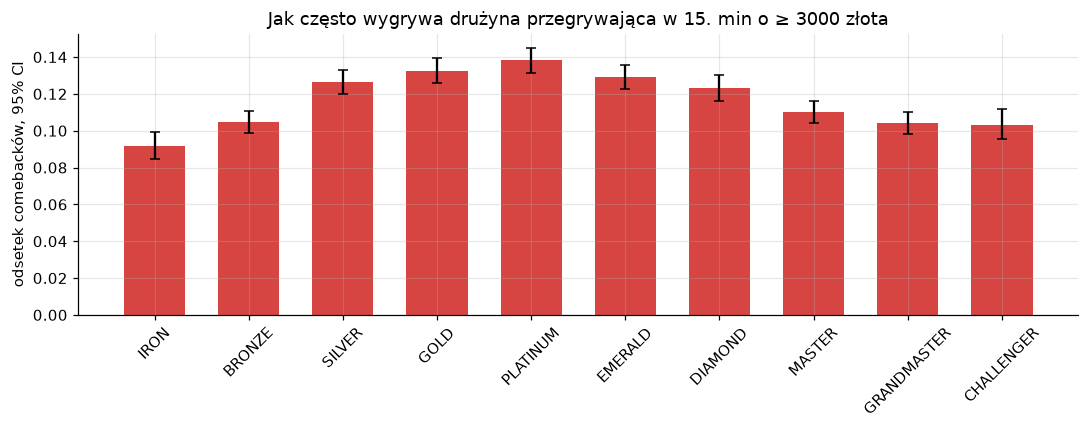

,sum,size,comeback_rate,ci_low,ci_high
seed_tier,,,,,
IRON,548,5979,0.0917,0.0846,0.0992
BRONZE,1063,10174,0.1045,0.0987,0.1106
SILVER,1249,9894,0.1262,0.1198,0.1329
GOLD,1299,9806,0.1325,0.1259,0.1393
PLATINUM,1370,9912,0.1382,0.1316,0.1452
EMERALD,1273,9874,0.1289,0.1225,0.1357
DIAMOND,1013,8236,0.1230,0.1161,0.1303
MASTER,1222,11113,0.1100,0.1043,0.1159
GRANDMASTER,1060,10183,0.1041,0.0983,0.1102


In [14]:
LEAD = 3000
behind = gd[gd.g15.abs() >= LEAD].copy()
behind['comeback'] = (behind.g15 > 0) != behind.blue_win      # wygrała drużyna, która przegrywała o >= 3000 złota
cb = behind.groupby('seed_tier').comeback.agg(['sum', 'size']).reindex(TIERS)
cb['comeback_rate'] = cb['sum'] / cb['size']
cb['ci_low'], cb['ci_high'] = wilson(cb['sum'], cb['size'])
chi2, p, dof, _ = stats.chi2_contingency(np.c_[cb['sum'], cb['size'] - cb['sum']])
rho, p_rho = stats.spearmanr(np.arange(len(cb)), cb.comeback_rate)
print(f'Comeback przy stracie >= {LEAD} złota w 15. min: {behind.comeback.mean():.2%} z {len(behind):,} meczów')
print(f'Test χ² jednorodności między rangami: χ² = {chi2:.1f}, df = {dof}, p = {p:.3g}; '
      f'korelacja Spearmana ranga ↔ comeback: ρ = {rho:.2f} (p = {p_rho:.3g})')

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cb))
ax.bar(x, cb.comeback_rate, color=RED, width=0.65)
ax.errorbar(x, cb.comeback_rate, yerr=[cb.comeback_rate - cb.ci_low, cb.ci_high - cb.comeback_rate],
            fmt='none', color='black', capsize=3)
ax.set_xticks(x, cb.index, rotation=45)
ax.set_ylabel('odsetek comebacków, 95% CI')
ax.set_title(f'Jak często wygrywa drużyna przegrywająca w 15. min o ≥ {LEAD} złota')
plt.tight_layout()
save_fig('comebacki')
plt.show()
cb

**Wnioski:**
* Zależność P(wygrana) od różnicy złota ma kształt **krzywej logistycznej**, a model dobrze pasuje do danych (punkty leżą na krzywych).
* **Ta sama przewaga złota znaczy więcej wcześniej w grze:** β = 0,53 na 1000 złota w 10. minucie, 0,40 w 15. i 0,36 w 20. Do 75% szans na wygraną potrzeba ok. **2,1 tys.** złota przewagi w 10. minucie, **2,7 tys.** w 15. i **3,1 tys.** w 20.
* Sam znak przewagi (kto ma więcej złota) wskazuje zwycięzcę w **69%** meczów w 10. minucie, **75%** w 15. i **78%** w 20.
* **Comebacki są rzadkie:** drużyna przegrywająca w 15. minucie o ≥ 3000 złota wygrywa tylko w **11,8%** przypadków.
* Odsetek comebacków **różni się między rangami** (χ² = 173, p ≈ 10⁻³²), ale **nie monotonicznie** (Spearman ρ = −0,12, p = 0,75), lecz w kształcie odwróconego U: najmniej w IRON (9,2%) i BRONZE (10,5%), najwięcej w PLATINUM (13,8%), i znowu mniej w MASTER+ (ok. 10–11%). Na najniższym poziomie przegrywająca drużyna rzadko potrafi się odbudować, a na najwyższym wygrywający skutecznie zamieniają przewagę na zwycięstwo.

## 6. Analiza 4: championy – popularność a skuteczność

Rozwijamy graczy (`$unwind` po `players`) i dla każdego championa liczymy liczbę gier, **pick rate** (odsetek meczów, w których wystąpił) i **win rate** z 95% przedziałem Wilsona. Sprawdzamy:
* którzy championowie mają win rate istotnie różny od 50% (przedział ufności nie zawiera 0,5),
* czy popularność wiąże się ze skutecznością (korelacja Spearmana pick rate ↔ win rate),
* czy win rate championów różni się bardziej niż wynikałoby z przypadku (test χ² jednorodności).

Championów: 173; istotnie różnych od 50%: 74 (36 powyżej, 38 poniżej)
Po korekcie Bonferroniego istotnych: 30 (przy braku różnic oczekiwalibyśmy ok. 9 fałszywych alarmów bez korekty)
Test χ² jednorodności win rate: χ² = 1289, df = 172, p = 2.94e-170
Korelacja Spearmana pick rate ↔ win rate: ρ = -0.026, p = 0.735


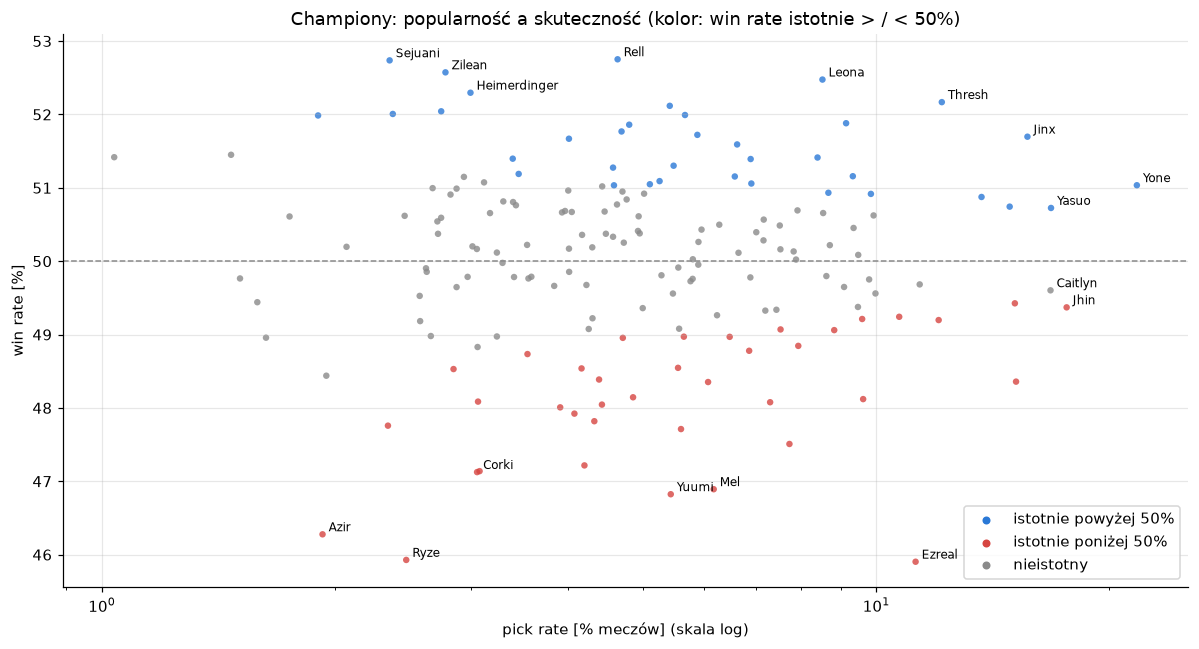

Najwyższy win rate:


,champion,glowna_rola,gier,pick_rate,win_rate,ci_low,ci_high,kda
143,Rell,UTILITY,9139,0.0464,0.5275,0.5173,0.5377,4.4363
137,Sejuani,JUNGLE,4640,0.0235,0.5274,0.5130,0.5417,4.8948
61,Zilean,UTILITY,5478,0.0278,0.5257,0.5125,0.5389,4.9317
172,Leona,UTILITY,16804,0.0852,0.5248,0.5172,0.5323,3.6636
122,Heimerdinger,TOP,5901,0.0299,0.5230,0.5102,0.5357,2.5127
52,Thresh,UTILITY,23963,0.1216,0.5217,0.5154,0.5280,4.1405
134,Xayah,BOTTOM,10672,0.0541,0.5212,0.5117,0.5306,3.3488
153,Rammus,JUNGLE,5409,0.0274,0.5204,0.5071,0.5337,4.4532
162,Belveth,JUNGLE,4684,0.0238,0.5201,0.5058,0.5344,3.5975
121,Fizz,MIDDLE,11167,0.0566,0.5199,0.5107,0.5292,3.4819


Najniższy win rate:


,champion,glowna_rola,gier,pick_rate,win_rate,ci_low,ci_high,kda
22,Ezreal,BOTTOM,22166,0.1124,0.4590,0.4525,0.4656,3.2144
7,Ryze,MIDDLE,4875,0.0247,0.4593,0.4453,0.4733,2.9941
150,Azir,MIDDLE,3801,0.0193,0.4628,0.4470,0.4787,2.4544
56,Yuumi,UTILITY,10704,0.0543,0.4682,0.4588,0.4777,6.6278
104,Mel,MIDDLE,12162,0.0617,0.4689,0.4601,0.4778,3.0442
13,Corki,BOTTOM,6018,0.0305,0.4713,0.4587,0.4839,2.7844
116,Orianna,MIDDLE,6063,0.0308,0.4714,0.4588,0.4840,3.4559
11,Varus,BOTTOM,8281,0.0420,0.4722,0.4614,0.4829,2.6969
0,Lucian,BOTTOM,15233,0.0773,0.4751,0.4672,0.4830,3.0469
63,Karma,UTILITY,11035,0.0560,0.4771,0.4678,0.4864,4.0112


In [15]:
champs = agg('games', [
    {'$unwind': '$players'},
    {'$group': {'_id': '$players.champion', 'gier': {'$sum': 1},
                'wygranych': {'$sum': {'$cond': ['$players.win', 1, 0]}},
                'kda': {'$avg': {'$divide': [{'$add': ['$players.kills', '$players.assists']},
                                             {'$max': ['$players.deaths', 1]}]}},
                'rola': {'$push': '$players.position'}}},
    {'$project': {'gier': 1, 'wygranych': 1, 'kda': 1,
                  'glowna_rola': {'$first': {'$sortArray': {
                      'input': {'$map': {'input': {'$setUnion': ['$rola']}, 'as': 'r', 'in': {
                          'r': '$$r', 'c': {'$size': {'$filter': {'input': '$rola', 'cond': {'$eq': ['$$this', '$$r']}}}}}}},
                      'sortBy': {'c': -1}}}}}},
]).rename(columns={'_id': 'champion'})
champs['glowna_rola'] = champs.glowna_rola.str['r']
champs['pick_rate'] = champs.gier / n_games
champs['win_rate'] = champs.wygranych / champs.gier
champs['ci_low'], champs['ci_high'] = wilson(champs.wygranych, champs.gier)
# korekta Bonferroniego: 173 testy naraz, więc poziom istotności 0,05 / liczba championów
bonf_low, bonf_high = wilson(champs.wygranych, champs.gier, z=stats.norm.ppf(1 - 0.025 / len(champs)))
champs['istotny_bonferroni'] = (bonf_low > 0.5) | (bonf_high < 0.5)
champs['istotny'] = np.select([champs.ci_low > 0.5, champs.ci_high < 0.5], ['powyżej 50%', 'poniżej 50%'], 'nieistotny')

chi2, p, dof, _ = stats.chi2_contingency(np.c_[champs.wygranych, champs.gier - champs.wygranych])
rho, p_rho = stats.spearmanr(champs.pick_rate, champs.win_rate)
print(f'Championów: {len(champs)}; istotnie różnych od 50%: {(champs.istotny != "nieistotny").sum()} '
      f'({(champs.istotny == "powyżej 50%").sum()} powyżej, {(champs.istotny == "poniżej 50%").sum()} poniżej)')
print(f'Po korekcie Bonferroniego istotnych: {champs.istotny_bonferroni.sum()} '
      f'(przy braku różnic oczekiwalibyśmy ok. {0.05 * len(champs):.0f} fałszywych alarmów bez korekty)')
print(f'Test χ² jednorodności win rate: χ² = {chi2:.0f}, df = {dof}, p = {p:.3g}')
print(f'Korelacja Spearmana pick rate ↔ win rate: ρ = {rho:.3f}, p = {p_rho:.3g}')

fig, ax = plt.subplots(figsize=(11, 6))
colors = champs.istotny.map({'powyżej 50%': BLUE, 'poniżej 50%': RED, 'nieistotny': GREY})
ax.scatter(champs.pick_rate * 100, champs.win_rate * 100, s=18, c=colors, alpha=0.8, linewidths=0)
for _, r in pd.concat([champs.nlargest(6, 'win_rate'), champs.nsmallest(6, 'win_rate'), champs.nlargest(5, 'pick_rate')]).drop_duplicates('champion').iterrows():
    ax.annotate(r.champion, (r.pick_rate * 100, r.win_rate * 100), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax.axhline(50, color=GREY, ls='--', lw=1)
ax.set_xscale('log')
ax.set_xlabel('pick rate [% meczów] (skala log)')
ax.set_ylabel('win rate [%]')
ax.set_title('Championy: popularność a skuteczność (kolor: win rate istotnie > / < 50%)')
for label, c in [('istotnie powyżej 50%', BLUE), ('istotnie poniżej 50%', RED), ('nieistotny', GREY)]:
    ax.scatter([], [], c=c, s=18, label=label)
ax.legend(loc='lower right')
plt.tight_layout()
save_fig('championy')
plt.show()

cols = ['champion', 'glowna_rola', 'gier', 'pick_rate', 'win_rate', 'ci_low', 'ci_high', 'kda']
print('Najwyższy win rate:')
display(champs.nlargest(10, 'win_rate')[cols])
print('Najniższy win rate:')
display(champs.nsmallest(10, 'win_rate')[cols])

**Wnioski:**
* **Win rate championów różni się istotnie** (test χ² jednorodności: p ≈ 10⁻¹⁷⁰), ale w wąskim zakresie: od ok. **45,9%** (Ezreal, Ryze) do ok. **52,8%** (Rell, Sejuani). To świadczy o dobrym zbalansowaniu gry.
* 74 ze 173 championów ma win rate istotnie różny od 50% (36 powyżej, 38 poniżej), a **30 nawet po korekcie Bonferroniego** na wielokrotne testowanie. Przy braku różnic spodziewalibyśmy się ok. 9 przypadkowych wyników bez korekty.
* Wśród najskuteczniejszych dominują **supporty i tanki** (Rell, Leona, Thresh, Zilean, Sejuani, Rammus), a wśród najsłabszych **mechanicznie trudni strzelcy i magowie** (Ezreal, Ryze, Azir, Corki, Orianna), którzy wymagają opanowania.
* **Popularność nie idzie w parze ze skutecznością** (Spearman ρ = −0,03, p = 0,74). Ezreal jest wybierany w 11% meczów, a ma najniższy win rate.
* **Wysokie KDA nie oznacza wygranych:** Yuumi ma najwyższe KDA (6,6), a win rate tylko 46,8%.

## 7. Podsumowanie

| etap | realizacja |
|---|---|
| **źródło danych** | oficjalne Riot Games API (`match-v5`, `league-v4`), pobierane przez osobną aplikację (collector) |
| **zapis** | ok. 172 GB surowego JSON (1,55 mln rekordów) zaimportowane do MongoDB w Dockerze: `matches`, `timelines`, `ranks` (ok. 21,6 GB dokumentów, 3,3 GB na dysku) |
| **czyszczenie** | odrzucanie duplikatów przez `_id`, kontrola typu meczu i spójności struktury, usunięcie meczów przerwanych, remake'ów, poddań przed 10. minutą i meczów bez ról; zostaje ok. 197 tys. meczów (97,1%) w kolekcji `games` |
| **analiza 1: strona mapy** | brak przewagi ogółem (49,9%, p = 0,24), ale istotna zależność od rangi: blue lepszy w niższych rangach, red w MASTER+ |
| **analiza 2: pierwsze cele** | pierwsza wieża to najsilniejszy wskaźnik z wczesnej gry (69,7% wygranych, OR ≈ 5,2); first blood daje tylko 57% |
| **analiza 3: przewaga złota** | zależność logistyczna; 75% szans przy ok. 2,7 tys. złota przewagi w 15. min; comeback z −3 tys. tylko w 11,8% meczów, najrzadszy w IRON i MASTER+ |
| **analiza 4: championy** | win rate 46–53%, 30 championów istotnie różnych od 50% po korekcie Bonferroniego; popularność nie wiąże się ze skutecznością |

Wszystkie analizy są wykonywane **potokami agregacji MongoDB** (`$group`, `$unwind`, `$bucket`, `$facet`, `$lookup`, `$merge`, `$out`). Do Pythona trafiają tylko zagregowane wyniki, a testy statystyczne liczymy w `scipy`.